In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from IPython.display import display

df = pd.read_excel("Online Retail.xlsx")

In [2]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Missing values:


,Missing Values
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [3]:
clean_df= df.copy()

CUSTOMER AND SALES SUMMARY
----------------------------------------
Unique customers: 4372
Unique products: 4070
Unique invoices: 25900
Countries: 38
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Total revenue: £ 9747747.93

TOP 10 PRODUCTS BY QUANTITY SOLD


,Description,Quantity
0,WORLD WAR 2 GLIDERS ASSTD DESIGNS,53847
1,JUMBO BAG RED RETROSPOT,47363
2,ASSORTED COLOUR BIRD ORNAMENT,36381
3,POPCORN HOLDER,36334
4,PACK OF 72 RETROSPOT CAKE CASES,36039
5,WHITE HANGING HEART T-LIGHT HOLDER,35317
6,RABBIT NIGHT LIGHT,30680
7,MINI PAINT SET VINTAGE,26437
8,PACK OF 12 LONDON TISSUES,26315
9,PACK OF 60 PINK PAISLEY CAKE CASES,24753



TOP 10 COUNTRIES BY REVENUE


,Country,Revenue
0,United Kingdom,8187806.364
1,Netherlands,284661.540
2,EIRE,263276.820
3,Germany,221698.210
4,France,197403.900
5,Australia,137077.270
6,Switzerland,56385.350
7,Spain,54774.580
8,Belgium,40910.960
9,Sweden,36595.910


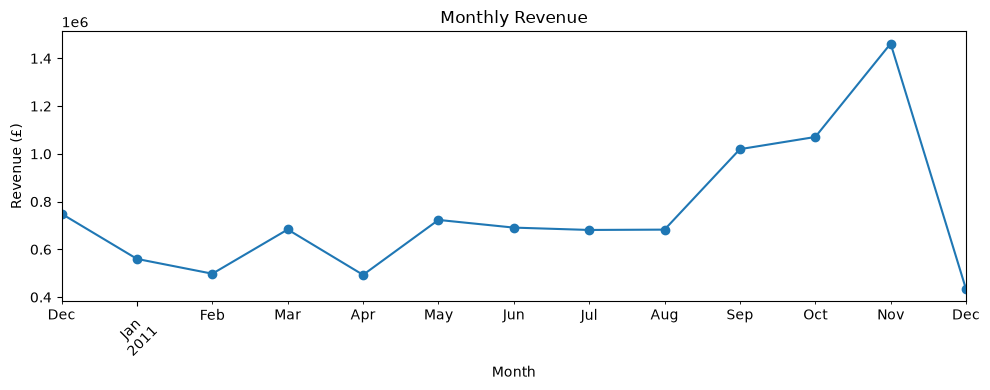

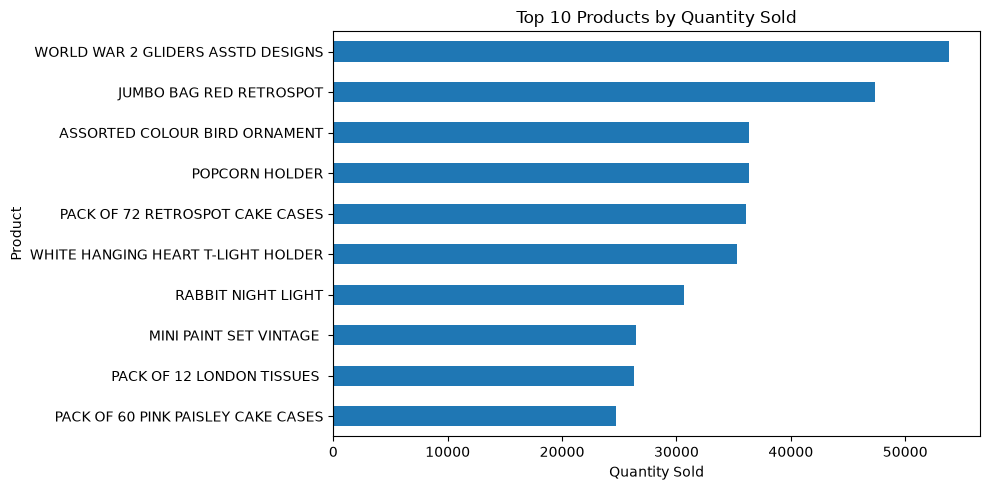

In [4]:
# Exploratory Data Analysis (EDA)

# Calculate total sales for each transaction row
clean_df["Revenue"] = clean_df["Quantity"] * clean_df["UnitPrice"]

# Overall dataset summary
print("CUSTOMER AND SALES SUMMARY")
print("-" * 40)
print("Unique customers:", clean_df["CustomerID"].nunique())
print("Unique products:", clean_df["StockCode"].nunique())
print("Unique invoices:", clean_df["InvoiceNo"].nunique())
print("Countries:", clean_df["Country"].nunique())
print("Date range:", clean_df["InvoiceDate"].min(), "to", clean_df["InvoiceDate"].max())
print("Total revenue: £", round(clean_df["Revenue"].sum(), 2))

# Top 10 products by quantity sold
top_products = (
    clean_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTOP 10 PRODUCTS BY QUANTITY SOLD")
display(top_products.reset_index())

# Top 10 countries by revenue
top_countries = (
    clean_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTOP 10 COUNTRIES BY REVENUE")
display(top_countries.reset_index())

# Monthly revenue trend
monthly_revenue = (
    clean_df.set_index("InvoiceDate")["Revenue"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(10, 4))
monthly_revenue.plot(marker="o")
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot the most frequently purchased products
plt.figure(figsize=(10, 5))
top_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

CUSTOMER SEGMENT COUNTS


,Segment,Number of Customers
0,Low Engagement,1305
1,Regular,1248
2,Loyal / Active,1130
3,At Risk,689



RFM SUMMARY


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346.0,326,2,0.00,1,2,1,121,Low Engagement
1,12347.0,2,7,4310.00,5,4,5,545,Loyal / Active
2,12348.0,75,4,1797.24,2,3,4,234,At Risk
3,12349.0,19,1,1757.55,4,1,4,414,Regular
4,12350.0,310,1,334.40,1,1,2,112,Low Engagement
5,12352.0,36,11,1545.41,3,5,4,354,Regular
6,12353.0,204,1,89.00,1,1,1,111,Low Engagement
7,12354.0,232,1,1079.40,1,1,4,114,Regular
8,12355.0,214,1,459.40,1,1,2,112,Low Engagement
9,12356.0,23,3,2811.43,4,3,5,435,Regular


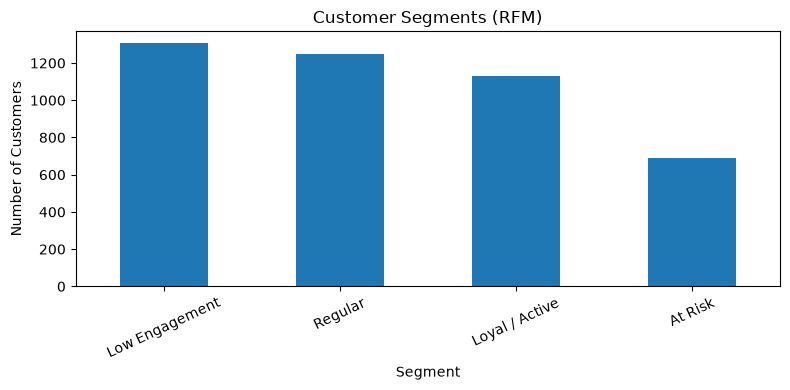

In [5]:
# Customer Segmentation using RFM Analysis

# Reference date: one day after the last transaction
reference_date = clean_df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = clean_df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

# Score customers from 1 to 5
# Higher recency score means a more recent purchase
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

# Simple customer segments
rfm["Segment"] = np.select(
    [
        (rfm["R_Score"] >= 4) & (rfm["F_Score"] >= 4),
        (rfm["R_Score"] <= 2) & (rfm["F_Score"] >= 3),
        (rfm["F_Score"] <= 2) & (rfm["M_Score"] <= 2)
    ],
    [
        "Loyal / Active",
        "At Risk",
        "Low Engagement"
    ],
    default="Regular"
)

print("CUSTOMER SEGMENT COUNTS")
display(
    rfm["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="Number of Customers")
)

print("\nRFM SUMMARY")
display(rfm.head(10))

# Visualize segments
plt.figure(figsize=(8, 4))
rfm["Segment"].value_counts().plot(kind="bar")
plt.title("Customer Segments (RFM)")
plt.xlabel("Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [6]:
# Analyze repeat purchases

# Count distinct invoices for each customer-product pair
customer_product = (
    clean_df.groupby(["CustomerID", "StockCode"])
    .agg(
        Purchase_Count=("InvoiceNo", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Last_Purchase=("InvoiceDate", "max")
    )
    .reset_index()
)

# Customer-product pairs purchased on multiple invoices
repeat_pairs = customer_product[
    customer_product["Purchase_Count"] >= 2
]

# Summary
total_pairs = len(customer_product)
repeated_pairs = len(repeat_pairs)

customers_with_repeats = repeat_pairs["CustomerID"].nunique()

print("CUSTOMER REPEAT-PURCHASE ANALYSIS")
print("-" * 40)
print("Unique customer-product pairs:", total_pairs)
print("Pairs purchased more than once:", repeated_pairs)
print(
    "Repeat-purchase pair rate:",
    round(repeated_pairs / total_pairs * 100, 2), "%"
)
print("Customers with repeat purchases:", customers_with_repeats)
print(
    "Customers with repeat purchases (%):",
    round(
        customers_with_repeats / clean_df["CustomerID"].nunique() * 100,
        2
    ), "%"
)

print("\nTOP 10 MOST REPEATED CUSTOMER-PRODUCT PAIRS")
display(
    repeat_pairs.sort_values(
        ["Purchase_Count", "Total_Quantity"],
        ascending=False
    ).head(10)
)

CUSTOMER REPEAT-PURCHASE ANALYSIS
----------------------------------------
Unique customer-product pairs: 267615
Pairs purchased more than once: 63484
Repeat-purchase pair rate: 23.72 %
Customers with repeat purchases: 2803
Customers with repeat purchases (%): 64.11 %

TOP 10 MOST REPEATED CUSTOMER-PRODUCT PAIRS


,CustomerID,StockCode,Purchase_Count,Total_Quantity,Last_Purchase
119844,14911.0,C2,85,83,2011-12-05 10:18:00
251152,17841.0,79321,64,587,2011-12-08 12:07:00
118697,14911.0,22423,55,316,2011-12-07 11:42:00
250347,17841.0,21927,54,186,2011-12-01 19:42:00
250570,17841.0,22467,47,269,2011-12-06 14:23:00
250516,17841.0,22355,46,169,2011-11-20 15:00:00
250362,17841.0,21975,46,118,2011-11-29 17:52:00
250354,17841.0,21935,41,92,2011-12-08 12:07:00
250578,17841.0,22475,41,84,2011-12-08 12:07:00
250283,17841.0,21672,38,175,2011-12-06 14:23:00


In [7]:
# Split data into training and testing sets
clean_df["InvoiceDate"] = pd.to_datetime(clean_df["InvoiceDate"])

cutoff_date = clean_df["InvoiceDate"].max() - pd.Timedelta(days=30)

train_data = clean_df[clean_df["InvoiceDate"] < cutoff_date].copy()
test_data = clean_df[clean_df["InvoiceDate"] >= cutoff_date].copy()

# Keep only valid customer transactions
train_data = train_data.dropna(subset=["CustomerID", "StockCode"])
test_data = test_data.dropna(subset=["CustomerID", "StockCode"])

# Create a dictionary of products purchased by each test customer
test_purchases = (
    test_data.groupby("CustomerID")["StockCode"]
    .apply(set)
    .to_dict()
)

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))
print("Test customers:", len(test_purchases))

Training rows: 340197
Testing rows: 66632
Test customers: 1695


In [8]:
# Create a dictionary of products purchased by each test customer
test_purchases = (
    test_data.groupby("CustomerID")["StockCode"]
    .apply(set)
    .to_dict()
)

print("Customers in test set:", len(test_purchases))

# Create a binary customer-product purchase matrix
train_binary = pd.crosstab(
    train_data["CustomerID"],
    train_data["StockCode"]
).gt(0).astype(int)

print("Training matrix shape:", train_binary.shape)

Customers in test set: 1695
Training matrix shape: (4106, 3644)


In [9]:
# Count how many times each customer purchased each product
repeat_counts = (
    train_data.groupby(["CustomerID", "StockCode"])["InvoiceNo"]
    .nunique()
    .rename("PurchaseCount")
)

# Calculate similarity between customers
from sklearn.metrics.pairwise import cosine_similarity

similarity_array = cosine_similarity(train_binary)

train_similarity = pd.DataFrame(
    similarity_array,
    index=train_binary.index,
    columns=train_binary.index
)

print("Similarity matrix shape:", train_similarity.shape)

Similarity matrix shape: (4106, 4106)


In [10]:
# Refined evaluation: repeat purchases vs new-product recommendations

def evaluate_refined(method, k=3):
    hits = 0
    total_recs = 0
    evaluated = 0

    for customer_id, actual_products in test_purchases.items():
        if customer_id not in train_binary.index:
            continue

        bought = set(
            train_binary.columns[train_binary.loc[customer_id] > 0]
        )

        # Repeat-purchase candidates ranked by previous invoice count
        cp = repeat_counts.loc[
            repeat_counts.index.get_level_values("CustomerID") == customer_id
        ]
        repeat_ranked = (
            cp.sort_values(ascending=False)
            .index.get_level_values("StockCode")
            .tolist()
        )

        # New-product candidates from collaborative filtering
        similarities = train_similarity.loc[customer_id].drop(
            customer_id, errors="ignore"
        ).nlargest(30)

        neighbor_purchases = train_binary.loc[similarities.index]
        cf_scores = neighbor_purchases.T.dot(similarities)
        cf_scores = cf_scores[
            ~cf_scores.index.isin(bought)
        ].sort_values(ascending=False)

        new_ranked = cf_scores[cf_scores > 0].index.tolist()

        if method == "repeat":
            candidates = repeat_ranked
        elif method == "cf":
            candidates = new_ranked
        else:
            # Hybrid: two repeat items, then one new item
            candidates = repeat_ranked[:2] + new_ranked

        # Unique candidates, no popularity fallback
        recs = []
        for product in candidates:
            if product not in recs:
                recs.append(product)
            if len(recs) == k:
                break

        if len(recs) != k:
            continue

        hits += len(set(recs) & actual_products)
        total_recs += len(recs)
        evaluated += 1

    return {
        "Method": method,
        "Customers evaluated": evaluated,
        "Hits": hits,
        "Precision@3": round(hits / total_recs, 4) if total_recs else 0
    }


refined_results = pd.DataFrame([
    evaluate_refined("cf"),
    evaluate_refined("repeat"),
    evaluate_refined("hybrid")
])

display(refined_results)

,Method,Customers evaluated,Hits,Precision@3
0,cf,1429,342,0.0798
1,repeat,1409,1360,0.3217
2,hybrid,1429,1100,0.2566


In [11]:
# Sanity check for repeat-purchase recommendations

repeat_hits = 0
repeat_slots = 0
repeat_customers = 0
duplicate_recommendations = 0

for customer_id, actual_products in test_purchases.items():
    if customer_id not in train_binary.index:
        continue

    cp = repeat_counts.loc[
        repeat_counts.index.get_level_values("CustomerID") == customer_id
    ]

    ranked = (
        cp.sort_values(ascending=False)
        .index.get_level_values("StockCode")
        .tolist()
    )

    recs = list(dict.fromkeys(ranked))[:3]

    if len(recs) != 3:
        continue

    repeat_customers += 1
    repeat_slots += len(recs)
    repeat_hits += len(set(recs) & actual_products)

    if len(recs) != len(set(recs)):
        duplicate_recommendations += 1

print("Customers evaluated:", repeat_customers)
print("Total recommendation slots:", repeat_slots)
print("Hits:", repeat_hits)
print("Precision@3:", round(repeat_hits / repeat_slots, 4) if repeat_slots else 0)
print("Customers with duplicate recommendations:", duplicate_recommendations)

Customers evaluated: 1409
Total recommendation slots: 4227
Hits: 1360
Precision@3: 0.3217
Customers with duplicate recommendations: 0


In [12]:
# تعداد دفعات خرید هر محصول توسط هر مشتری در داده‌های آموزشی
repeat_counts = (
    train_data.groupby(["CustomerID", "StockCode"])["InvoiceNo"]
    .nunique()
)

# فقط محصولاتی که در حداقل دو فاکتور جداگانه خریداری شده‌اند
true_repeat_counts = repeat_counts[repeat_counts >= 2]

print("Customer-product pairs in training:", len(repeat_counts))
print("Pairs purchased in 2+ invoices:", len(true_repeat_counts))
print("Percentage eligible for repeat recommendations:",
      round(len(true_repeat_counts) / len(repeat_counts) * 100, 2), "%")

Customer-product pairs in training: 232361
Pairs purchased in 2+ invoices: 51484
Percentage eligible for repeat recommendations: 22.16 %


In [13]:
# Map product codes to product names
product_names = (
    clean_df.dropna(subset=["StockCode", "Description"])
    .drop_duplicates(subset=["StockCode"])
    .set_index("StockCode")["Description"]
    .to_dict()
)

print("Product names loaded:", len(product_names))

Product names loaded: 3958


In [14]:
# مدل ترکیبی پیشنهاد محصول - نسخه اصلاح‌شده

customer_product_stats = (
    train_data.groupby(["CustomerID", "StockCode"])
    .agg(
        Purchase_Count=("InvoiceNo", "nunique"),
        Last_Purchase=("InvoiceDate", "max")
    )
    .reset_index()
)

def recommend_hybrid(customer_id):
    if customer_id not in train_binary.index:
        return []

    customer_history = customer_product_stats[
        customer_product_stats["CustomerID"] == customer_id
    ].copy()

    recommendations = []
    selected_codes = set()

    # 1) پیشنهاد محصول پرتکرار
    repeated = customer_history[
        customer_history["Purchase_Count"] >= 2
    ].sort_values(
        ["Purchase_Count", "Last_Purchase"],
        ascending=[False, False]
    )

    if not repeated.empty:
        row = repeated.iloc[0]
        product = row["StockCode"]

        recommendations.append({
            "CustomerID": customer_id,
            "Recommended Product": product_names.get(
                product, str(product)
            ),
            "StockCode": product,
            "Reason": "خرید تکراری",
            "Purchase Count": int(row["Purchase_Count"])
        })
        selected_codes.add(product)

    # محصولات خریداری‌شده توسط مشتری
    bought_codes = set(
        train_binary.columns[train_binary.loc[customer_id] > 0]
    )

    # 2) پیشنهاد محصول خریداری‌شده در زمان اخیر
    recent = customer_history.sort_values(
        "Last_Purchase", ascending=False
    )

    for _, row in recent.iterrows():
        product = row["StockCode"]

        if product not in selected_codes:
            recommendations.append({
                "CustomerID": customer_id,
                "Recommended Product": product_names.get(
                    product, str(product)
                ),
                "StockCode": product,
                "Reason": "خرید اخیر",
                "Purchase Count": int(row["Purchase_Count"])
            })
            selected_codes.add(product)
            break

    # 3) پیشنهاد محصول جدید از مشتریان مشابه
    similarities = (
        train_similarity.loc[customer_id]
        .drop(customer_id, errors="ignore")
        .nlargest(30)
    )

    if not similarities.empty:
        neighbor_purchases = train_binary.loc[similarities.index]
        scores = neighbor_purchases.T.dot(similarities).sort_values(
            ascending=False
        )

        for product, score in scores.items():
            if (
                product not in bought_codes
                and product not in selected_codes
                and score > 0
            ):
                recommendations.append({
                    "CustomerID": customer_id,
                    "Recommended Product": product_names.get(
                        product, str(product)
                    ),
                    "StockCode": product,
                    "Reason": "پیشنهاد مشتریان مشابه",
                    "Purchase Count": 0
                })
                selected_codes.add(product)
                break

    return recommendations[:3]

In [15]:
sample_customer = train_data["CustomerID"].value_counts().index[0]

display(pd.DataFrame(recommend_hybrid(sample_customer)))

,CustomerID,Recommended Product,StockCode,Reason,Purchase Count
0,17841.0,CHILLI LIGHTS,79321,خرید تکراری,59
1,17841.0,Manual,M,خرید اخیر,10
2,17841.0,HANGING HEART JAR T-LIGHT HOLDER,84978,پیشنهاد مشتریان مشابه,0


In [16]:
# بررسی کدهای غیرمعمول و توضیحات مرتبط
display(
    clean_df[
        clean_df["StockCode"].astype(str).str.len() <= 2
    ][["StockCode", "Description"]]
    .drop_duplicates()
    .sort_values("StockCode")
    .head(50)
)

,StockCode,Description
299982,B,Adjust bad debt
1423,C2,CARRIAGE
453999,C2,NaN
141,D,Discount
2239,M,Manual
14436,S,SAMPLES
40383,m,Manual


In [17]:
# حذف موارد غیرمحصولی از داده‌های مدل
excluded_codes = ["C2", "M"]

train_data = train_data[
    ~train_data["StockCode"].astype(str).isin(excluded_codes)
].copy()

test_data = test_data[
    ~test_data["StockCode"].astype(str).isin(excluded_codes)
].copy()

# بازسازی ماتریس خرید آموزش
train_matrix = train_data.pivot_table(
    index="CustomerID",
    columns="StockCode",
    values="Quantity",
    aggfunc="sum",
    fill_value=0
)

train_binary = (train_matrix > 0).astype(int)

# محاسبه مجدد شباهت مشتریان
from sklearn.metrics.pairwise import cosine_similarity

train_similarity = pd.DataFrame(
    cosine_similarity(train_binary),
    index=train_binary.index,
    columns=train_binary.index
)

# بازسازی تاریخچه خرید هر مشتری
customer_product_stats = (
    train_data.groupby(["CustomerID", "StockCode"])
    .agg(
        Purchase_Count=("InvoiceNo", "nunique"),
        Last_Purchase=("InvoiceDate", "max")
    )
    .reset_index()
)

# به‌روزرسانی خریدهای واقعی در دوره آزمایش
test_purchases = test_data.groupby("CustomerID")["StockCode"].apply(set)

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))
print("Excluded codes remaining:",
      train_data["StockCode"].astype(str).isin(excluded_codes).sum())

Training rows: 339673
Testing rows: 66557
Excluded codes remaining: 0


In [18]:
# ارزیابی مدل ترکیبی

total_hits = 0
total_slots = 0
customers_evaluated = 0
customers_with_three = 0
customers_with_hit = 0

for customer_id, actual_products in test_purchases.items():
    if customer_id not in train_binary.index:
        continue

    recommendations = recommend_hybrid(customer_id)

    recommended_codes = list(dict.fromkeys(
        item["StockCode"] for item in recommendations
    ))

    if not recommended_codes:
        continue

    customers_evaluated += 1
    total_slots += len(recommended_codes)

    hits = len(set(recommended_codes) & actual_products)
    total_hits += hits

    if len(recommended_codes) == 3:
        customers_with_three += 1

    if hits > 0:
        customers_with_hit += 1

precision = total_hits / total_slots if total_slots else 0
success_rate = (
    customers_with_hit / customers_evaluated
    if customers_evaluated else 0
)

print("Customers evaluated:", customers_evaluated)
print("Customers receiving 3 recommendations:", customers_with_three)
print("Total recommendation slots:", total_slots)
print("Hits:", total_hits)
print(f"Precision over recommended slots: {precision:.2%}")
print(f"Customer success rate: {success_rate:.2%}")

Customers evaluated: 1427
Customers receiving 3 recommendations: 1127
Total recommendation slots: 3977
Hits: 955
Precision over recommended slots: 24.01%
Customer success rate: 51.51%


In [19]:
customers_with_hit = 0
customers_evaluated = 0
customers_with_three = 0

for customer_id, actual_products in test_purchases.items():
    if customer_id not in train_binary.index:
        continue

    recommendations = recommend_hybrid(customer_id)

    recommended_codes = list(dict.fromkeys(
        item["StockCode"] for item in recommendations
    ))

    if not recommended_codes:
        continue

    customers_evaluated += 1

    if len(recommended_codes) == 3:
        customers_with_three += 1

    if set(recommended_codes) & actual_products:
        customers_with_hit += 1

success_rate = (
    customers_with_hit / customers_evaluated
    if customers_evaluated else 0
)

print("Customers evaluated:", customers_evaluated)
print("Customers receiving 3 recommendations:", customers_with_three)
print("Customers who bought at least 1 recommendation:", customers_with_hit)
print(f"Customer success rate: {success_rate:.2%}")

Customers evaluated: 1427
Customers receiving 3 recommendations: 1127
Customers who bought at least 1 recommendation: 735
Customer success rate: 51.51%


In [20]:
no_hit_with_three = 0
no_hit_with_fewer = 0

for customer_id, actual_products in test_purchases.items():
    if customer_id not in train_binary.index:
        continue

    recommendations = recommend_hybrid(customer_id)
    recommended_codes = list(dict.fromkeys(
        item["StockCode"] for item in recommendations
    ))

    if set(recommended_codes) & actual_products:
        continue

    if len(recommended_codes) == 3:
        no_hit_with_three += 1
    else:
        no_hit_with_fewer += 1

print("No-hit customers with 3 recommendations:", no_hit_with_three)
print("No-hit customers with fewer than 3:", no_hit_with_fewer)

No-hit customers with 3 recommendations: 479
No-hit customers with fewer than 3: 213


In [21]:
# نسخه دوم مدل: پیشنهاد جایگزین با محبوبیت کلی محصولات

# محبوبیت هر محصول بر اساس تعداد فاکتورهای متمایز در داده آموزش
product_popularity = (
    train_data.groupby("StockCode")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

def recommend_hybrid_v2(customer_id):
    # دو پیشنهاد اول را از مدل قبلی می‌گیریم
    recommendations = recommend_hybrid(customer_id)

    if customer_id not in train_binary.index:
        return recommendations

    selected_codes = {
        item["StockCode"] for item in recommendations
    }

    # محصولات خریداری‌شده توسط خود مشتری
    bought_codes = set(
        train_binary.columns[train_binary.loc[customer_id] > 0]
    )

    # اگر هنوز سه پیشنهاد نداریم، محصولات محبوب را بررسی می‌کنیم
    for product in product_popularity.index:
        if product in bought_codes or product in selected_codes:
            continue

        recommendations.append({
            "CustomerID": customer_id,
            "Recommended Product": product_names.get(
                product, str(product)
            ),
            "StockCode": product,
            "Reason": "محصول محبوب فروشگاه",
            "Purchase Count": 0
        })

        selected_codes.add(product)

        if len(recommendations) == 3:
            break

    return recommendations[:3]


# آزمایش روی همان مشتری نمونه
display(pd.DataFrame(recommend_hybrid_v2(sample_customer)))

,CustomerID,Recommended Product,StockCode,Reason,Purchase Count
0,17841.0,CHILLI LIGHTS,79321,خرید تکراری,59
1,17841.0,POLYESTER FILLER PAD 40x40cm,46000S,خرید اخیر,13
2,17841.0,HANGING HEART JAR T-LIGHT HOLDER,84978,پیشنهاد مشتریان مشابه,0


In [22]:
def compare_models():
    results = []

    for model_name, model_func in [
        ("مدل فعلی", recommend_hybrid),
        ("مدل جدید", recommend_hybrid_v2)
    ]:
        evaluated = 0
        customers_with_three = 0
        customers_with_hit = 0

        for customer_id, actual_products in test_purchases.items():
            if customer_id not in train_binary.index:
                continue

            recommendations = model_func(customer_id)
            codes = list(dict.fromkeys(
                item["StockCode"] for item in recommendations
            ))

            if not codes:
                continue

            evaluated += 1

            if len(codes) == 3:
                customers_with_three += 1

            if set(codes) & actual_products:
                customers_with_hit += 1

        results.append({
            "Model": model_name,
            "Customers Evaluated": evaluated,
            "Customers Receiving 3": customers_with_three,
            "Customers with at Least 1 Hit": customers_with_hit,
            "Customer Success Rate (%)": round(
                customers_with_hit / evaluated * 100, 2
            ) if evaluated else 0
        })

    comparison = pd.DataFrame(results)
    display(comparison)

compare_models()

,Model,Customers Evaluated,Customers Receiving 3,Customers with at Least 1 Hit,Customer Success Rate (%)
0,مدل فعلی,1427,1127,735,51.51
1,مدل جدید,1427,1427,743,52.07


In [23]:
# بررسی عملکرد هر جایگاه پیشنهاد

slot_stats = {
    1: {"hits": 0, "customers": 0},
    2: {"hits": 0, "customers": 0},
    3: {"hits": 0, "customers": 0}
}

third_reason_stats = {}

for customer_id, actual_products in test_purchases.items():
    if customer_id not in train_binary.index:
        continue

    recommendations = recommend_hybrid_v2(customer_id)
    seen = set()
    unique_recommendations = []

    for item in recommendations:
        code = item["StockCode"]
        if code not in seen:
            unique_recommendations.append(item)
            seen.add(code)

    for position, item in enumerate(unique_recommendations[:3], start=1):
        slot_stats[position]["customers"] += 1

        if item["StockCode"] in actual_products:
            slot_stats[position]["hits"] += 1

        if position == 3:
            reason = item["Reason"]
            if reason not in third_reason_stats:
                third_reason_stats[reason] = {
                    "customers": 0,
                    "hits": 0
                }

            third_reason_stats[reason]["customers"] += 1

            if item["StockCode"] in actual_products:
                third_reason_stats[reason]["hits"] += 1

slot_results = []

for position, stats in slot_stats.items():
    slot_results.append({
        "Recommendation Position": position,
        "Customers Receiving": stats["customers"],
        "Hits": stats["hits"],
        "Hit Rate (%)": round(
            stats["hits"] / stats["customers"] * 100, 2
        ) if stats["customers"] else 0
    })

print("Performance by recommendation position:")
display(pd.DataFrame(slot_results))

print("Performance of the third recommendation by reason:")
reason_results = []

for reason, stats in third_reason_stats.items():
    reason_results.append({
        "Reason": reason,
        "Customers Receiving": stats["customers"],
        "Hits": stats["hits"],
        "Hit Rate (%)": round(
            stats["hits"] / stats["customers"] * 100, 2
        ) if stats["customers"] else 0
    })

display(pd.DataFrame(reason_results))

Performance by recommendation position:


,Recommendation Position,Customers Receiving,Hits,Hit Rate (%)
0,1,1427,538,37.70
1,2,1427,330,23.13
2,3,1427,101,7.08


Performance of the third recommendation by reason:


,Reason,Customers Receiving,Hits,Hit Rate (%)
0,پیشنهاد مشتریان مشابه,1127,88,7.81
1,محصول محبوب فروشگاه,300,13,4.33


In [24]:
# بررسی خروجی مدل اصلی برای ۱۰ مشتری نمونه

sample_customers = (
    train_data["CustomerID"]
    .value_counts()
    .head(10)
    .index
)

final_recommendations = []

for customer_id in sample_customers:
    final_recommendations.extend(
        recommend_hybrid(customer_id)
    )

final_table = pd.DataFrame(final_recommendations)

display(final_table)

,CustomerID,Recommended Product,StockCode,Reason,Purchase Count
0,17841.0,CHILLI LIGHTS,79321,خرید تکراری,59
1,17841.0,POLYESTER FILLER PAD 40x40cm,46000S,خرید اخیر,13
2,17841.0,HANGING HEART JAR T-LIGHT HOLDER,84978,پیشنهاد مشتریان مشابه,0
3,14911.0,REGENCY CAKESTAND 3 TIER,22423,خرید تکراری,46
4,14911.0,BISCUIT TIN 50'S CHRISTMAS,23247,خرید اخیر,4
5,14911.0,LUNCH BOX I LOVE LONDON,22659,پیشنهاد مشتریان مشابه,0
6,12748.0,REX CASH+CARRY JUMBO SHOPPER,21034,خرید تکراری,24
7,12748.0,LUNCH BAG SPACEBOY DESIGN,22382,خرید اخیر,7
8,12748.0,JUMBO BAG RED RETROSPOT,85099B,پیشنهاد مشتریان مشابه,0
9,14096.0,CRUK Commission,CRUK,خرید تکراری,11


In [25]:
# حذف موارد غیرکالایی از جدول پیشنهادها
excluded_codes = {"DOT", "M", "C2"}

final_table_clean = final_table[
    ~final_table["StockCode"].astype(str).isin(excluded_codes)
].copy()

display(final_table_clean)

final_table_clean.to_csv(
    "final_recommendations.csv",
    index=False,
    encoding="utf-8-sig"
)

,CustomerID,Recommended Product,StockCode,Reason,Purchase Count
0,17841.0,CHILLI LIGHTS,79321,خرید تکراری,59
1,17841.0,POLYESTER FILLER PAD 40x40cm,46000S,خرید اخیر,13
2,17841.0,HANGING HEART JAR T-LIGHT HOLDER,84978,پیشنهاد مشتریان مشابه,0
3,14911.0,REGENCY CAKESTAND 3 TIER,22423,خرید تکراری,46
4,14911.0,BISCUIT TIN 50'S CHRISTMAS,23247,خرید اخیر,4
5,14911.0,LUNCH BOX I LOVE LONDON,22659,پیشنهاد مشتریان مشابه,0
6,12748.0,REX CASH+CARRY JUMBO SHOPPER,21034,خرید تکراری,24
7,12748.0,LUNCH BAG SPACEBOY DESIGN,22382,خرید اخیر,7
8,12748.0,JUMBO BAG RED RETROSPOT,85099B,پیشنهاد مشتریان مشابه,0
9,14096.0,CRUK Commission,CRUK,خرید تکراری,11


In [26]:
# ساخت مجدد جدول نهایی از صفر

sample_customers = (
    train_data["CustomerID"]
    .value_counts()
    .head(10)
    .index.tolist()
)

final_recommendations = []

for customer_id in sample_customers:
    recommendations = recommend_hybrid_v2(customer_id)

    seen = set()
    unique_recommendations = []

    for item in recommendations:
        code = str(item["StockCode"])
        if code not in seen and code not in {"DOT", "M", "C2"}:
            unique_recommendations.append(item)
            seen.add(code)

    bought_codes = set(
        train_binary.columns[
            train_binary.loc[customer_id] > 0
        ].astype(str)
    )

    for product_code in product_popularity.index:
        code = str(product_code)

        if code in seen or code in bought_codes or code in {"DOT", "M", "C2"}:
            continue

        unique_recommendations.append({
            "CustomerID": customer_id,
            "Recommended Product": product_names.get(
                product_code, str(product_code)
            ),
            "StockCode": product_code,
            "Reason": "محصول محبوب فروشگاه",
            "Purchase Count": 0
        })
        seen.add(code)

        if len(unique_recommendations) == 3:
            break

    final_recommendations.extend(unique_recommendations[:3])

final_table_clean = pd.DataFrame(final_recommendations)

final_table_clean.to_csv(
    "final_recommendations.csv",
    index=False,
    encoding="utf-8-sig"
)

print("تعداد کل پیشنهادها:", len(final_table_clean))
print(final_table_clean.groupby("CustomerID").size())
display(final_table_clean)

تعداد کل پیشنهادها: 30
CustomerID
12748.0    3
13089.0    3
13263.0    3
14096.0    3
14298.0    3
14606.0    3
14646.0    3
14911.0    3
15311.0    3
17841.0    3
dtype: int64


,CustomerID,Recommended Product,StockCode,Reason,Purchase Count
0,17841.0,CHILLI LIGHTS,79321,خرید تکراری,59
1,17841.0,POLYESTER FILLER PAD 40x40cm,46000S,خرید اخیر,13
2,17841.0,HANGING HEART JAR T-LIGHT HOLDER,84978,پیشنهاد مشتریان مشابه,0
3,14911.0,REGENCY CAKESTAND 3 TIER,22423,خرید تکراری,46
4,14911.0,BISCUIT TIN 50'S CHRISTMAS,23247,خرید اخیر,4
5,14911.0,LUNCH BOX I LOVE LONDON,22659,پیشنهاد مشتریان مشابه,0
6,12748.0,REX CASH+CARRY JUMBO SHOPPER,21034,خرید تکراری,24
7,12748.0,LUNCH BAG SPACEBOY DESIGN,22382,خرید اخیر,7
8,12748.0,JUMBO BAG RED RETROSPOT,85099B,پیشنهاد مشتریان مشابه,0
9,14096.0,CRUK Commission,CRUK,خرید تکراری,11


In [27]:
print(final_table_clean.groupby("CustomerID").size())

CustomerID
12748.0    3
13089.0    3
13263.0    3
14096.0    3
14298.0    3
14606.0    3
14646.0    3
14911.0    3
15311.0    3
17841.0    3
dtype: int64


In [28]:
# Simulated Conversation with the Smart Sales Assistant

conversation = [
    ("دستیار فروش", "سلام! خوش اومدید. با توجه به خریدهای قبلی‌تون، فکر کردم شاید چراغ تزئینی CHILLI LIGHTS و زیرانداز POLYESTER FILLER PAD 45x45cm براتون جالب باشن."),

    ("مشتری", "سلام! این چراغ CHILLI LIGHTS چه شکلیه؟ برای تزئین اتاق مناسبه؟"),

    ("دستیار فروش", "بله، این محصول در دستهٔ چراغ‌های تزئینی قرار می‌گیره و می‌تونه برای ایجاد فضایی گرم و متفاوت در اتاق یا دکور خونه مناسب باشه."),

    ("مشتری", "خوبه! قیمتش چقدره؟ عکسش رو هم می‌تونم ببینم؟"),

    ("دستیار فروش", "حتماً. می‌تونید تصویر و قیمت روز محصول رو در صفحهٔ فروشگاه بررسی کنید. اگر ظاهر و قیمتش با سلیقه‌تون هماهنگ بود، می‌تونید به سبد خرید اضافه‌اش کنید."),

    ("مشتری", "ممنون، اول عکس و قیمتش رو بررسی می‌کنم. اگه مناسب بود، می‌خرمش."),

    ("دستیار فروش", "خواهش می‌کنم! پیشنهادهای دیگه‌مون رو هم می‌تونید بررسی کنید. امیدوارم خرید خوبی داشته باشید.")
]

print("=" * 65)
print("گفت‌وگوی شبیه‌سازی‌شده با دستیار فروش هوشمند")
print("=" * 65)

for speaker, message in conversation:
    print(f"\n{speaker}: {message}")

print("\n" + "=" * 65)
print("پایان گفت‌وگو — شبیه‌سازی فرایند پیشنهاد محصول و احتمال خرید")

گفت‌وگوی شبیه‌سازی‌شده با دستیار فروش هوشمند

دستیار فروش: سلام! خوش اومدید. با توجه به خریدهای قبلی‌تون، فکر کردم شاید چراغ تزئینی CHILLI LIGHTS و زیرانداز POLYESTER FILLER PAD 45x45cm براتون جالب باشن.

مشتری: سلام! این چراغ CHILLI LIGHTS چه شکلیه؟ برای تزئین اتاق مناسبه؟

دستیار فروش: بله، این محصول در دستهٔ چراغ‌های تزئینی قرار می‌گیره و می‌تونه برای ایجاد فضایی گرم و متفاوت در اتاق یا دکور خونه مناسب باشه.

مشتری: خوبه! قیمتش چقدره؟ عکسش رو هم می‌تونم ببینم؟

دستیار فروش: حتماً. می‌تونید تصویر و قیمت روز محصول رو در صفحهٔ فروشگاه بررسی کنید. اگر ظاهر و قیمتش با سلیقه‌تون هماهنگ بود، می‌تونید به سبد خرید اضافه‌اش کنید.

مشتری: ممنون، اول عکس و قیمتش رو بررسی می‌کنم. اگه مناسب بود، می‌خرمش.

دستیار فروش: خواهش می‌کنم! پیشنهادهای دیگه‌مون رو هم می‌تونید بررسی کنید. امیدوارم خرید خوبی داشته باشید.

پایان گفت‌وگو — شبیه‌سازی فرایند پیشنهاد محصول و احتمال خرید
